# 06 — Embeddings e indexação da jurisprudência

Preparação da coleção vetorial de jurisprudência com o **mesmo backbone BGE-M3 da legislação**, mantendo a janela de 500 tokens com 100 de sobreposição. A geração integral só pode começar após a auditoria global do notebook 05; nenhuma saída parcial é promovida a corpus completo.

Legislação e jurisprudência mantêm seus tratamentos e suas coleções separados. Esta etapa não altera os notebooks, caches ou tabelas de legislação, nem executa LLM ou novo teste de chunking.

**Recorte de indexação e origem dos vetores.** A coleção cobre o **recorte de indexação do notebook 05**: 20.000 dos 169.821 candidatos consolidados, com 303.257 chunks e 300.902 textos únicos. Os 187 documentos dos experimentos e da avaliação estão incluídos. Os vetores foram calculados na **GPU T4 do Kaggle**, em **FP16 (autocast)**, por decisão registrada após o benchmark (cerca de 4,5 vezes mais rápido que float32). Eles foram renormalizados e **gravados em float32**. Em cada parte, uma amostra foi recalculada em float32, com cosseno mínimo de 0,999813 (tolerância de 0,9995). A compatibilidade com a legislação foi aprovada em float32 e em FP16.

Aqui, os vetores baixados foram conferidos por hash, dimensão, norma e mapeamento vetor/chunk e importados no cache local (`scripts/importar_embeddings_kaggle_jurisprudencia.py`). Os lotes deste notebook são montados a partir desse cache, sem recalcular vetores na CPU. A origem fica registrada em `reports/jurisprudencia/embeddings/importacao_kaggle.json` e na configuração dos embeddings.


## 1. Importação de bibliotecas e parâmetros

Modelo BAAI/bge-m3 no snapshot local identificado por hash, vetores densos de 1.024 dimensões gravados em float32 (calculados em FP16 no Kaggle) e normalização L2. O limite do encoder é 8.192 tokens; cada chunk deste corpus tem no máximo 500 tokens de texto e 502 com os especiais. Não se adiciona prefixo nem se aplica truncamento ao corpus.

In [1]:
from pathlib import Path
import sys,json,subprocess
import pandas as pd
from IPython.display import display,Markdown
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/jurisprudencia').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from worker.ingestao.jurisprudencia import embeddings_relatorio as painel
from worker.ingestao.jurisprudencia import embeddings_definitivos,proxima_etapa
from worker.evidencia.indices import jurisprudencia_pgvector
print('Backbone: BAAI/bge-m3; dimensão: 1024; dtype: float32; normalização L2.')

Backbone: BAAI/bge-m3; dimensão: 1024; dtype: float32; normalização L2.


## 2. Compatibilidade com legislação e custo computacional

O pré-flight confere os arquivos do modelo e tokenizador e compara três vetores de prova com o cache congelado de legislação. A chave e a ordem originais são lidas do manifesto preservado; não se reconstrói a chave antiga a partir de bibliotecas atuais nem se sobrescrevem os vetores existentes.

O benchmark usa oito textos artificiais de aproximadamente 500 tokens, apenas para estimar custo. A duração por milhão é uma extrapolação, não previsão garantida: hardware, tamanho dos lotes e repetições alteram o tempo real. A geração em escala depende da escolha entre CPU local de longa duração e o recurso de GPU informado pela pessoa usuária. Não se contrata serviço externo automaticamente.

In [2]:
ESTADO_EMBEDDINGS=painel.show_preflight(ROOT)

,modelo,revisao,dimensao,dtype,max_seq_length,normalizacao_l2,device
0,BAAI/bge-m3,5617a9f61b028005a4858fdac845db406aefb181,1024,float32,8192,True,cpu


,status,amostras,cosine_min,erro_absoluto_max,manifesto_legislacao_sha256,dataset_legislacao,indice_cache_legislacao,corpus_legislacao_regravado
0,compativel_na_prova_numerica,3,1.0,0.0,b47ab4afdc969d63eef4ba8c188617e256c4b9d766acae...,036e49f3a30a99ea706fce9be2f8301aabf5817c81e9f7...,d47b344618e40544062fabe978c9f65e8c996b9915ef5d...,False


,entradas,tokens_texto_por_entrada,segundos,segundos_por_chunk,horas_por_milhao_chunks,amostra
0,8,500,10.147321,1.268415,352.337535,artificial; apenas custo computacional


**Compatibilidade:** os três vetores transitórios de prova foram confrontados com o cache original de legislação, cujo hash e mapeamento foram verificados. A legislação não foi regravada. A medição artificial serve apenas para custo de execução; não mede qualidade jurídica.

,disponivel,erro_tipo,consulta_somente_leitura,observacao
0,False,ConnectionTimeout,True,Credenciais e texto da exceção não são registr...


,estado,preferencia_recurso,device,corpus_chunking,notebook_portatil,pacotes,autorun_apos_05,espera,sem_contratacao_externa,execucao,sessoes,atualizado_em_utc
0,embeddings_importados_e_indexados_pgvector,GPU do Kaggle (escolha da pessoa usuária em 16...,"cuda:0 (Kaggle, uma GPU)",0c83986fcd73e3ab2d4f0f922ae4868c14b49a3833c7ad...,output/kaggle/06_embeddings_gpu_kaggle.ipynb,output/kaggle/pacotes/ (scripts/exportar_pacot...,False,None,True,"Kaggle, GPU NVIDIA T4, FP16 (autocast) com con...","[lexia-embeddings-jurisprudencia (sessão 1, pa...",2026-11-17T00:21:16.518768+00:00


## 3. Entrada validada e encadeamento após o notebook 05

O executor exige `concluido.json` com `chunking_validado`, o manifesto integral dos lotes e o hash do tokenizador usado no chunking. O acompanhamento aguarda a atualização e a verificação finais do notebook 05 e mantém a versão do corpus fixada.

`politica_execucao.json` registra o recurso escolhido. Enquanto essa definição estiver pendente, o encadeamento não inicia a geração em escala. A opção abaixo permanece desativada para que “Executar tudo” seja leitura dos estados e não abra um segundo escritor.

In [3]:
EXECUTAR_ETAPA_06=False
if EXECUTAR_ETAPA_06:
    proxima_etapa.run(ROOT)
ESTADO_EMBEDDINGS=painel.show_progress(ROOT)

,status,dataset_id,chunks,esquema,manifesto_embeddings_sha256,tabelas_legislacao_alteradas,indice_aproximado_criado,observacao
0,indexacao_pgvector_validada,cdd4b73c92bc5f2237a31a3d8f666c8a339ce8982c98b7...,303257,lex_jurisprudencia,b38995455b74ccc51cd90c4bdc6e7792955e4c06fe482f...,False,False,Importação e releitura exatas. A avaliação de ...


**Separação de etapas:** o pré-flight não é vetorização integral. Cache parcial, lote concluído e coleção integral validada têm estados diferentes. Nenhuma taxa de acerto de respostas é inferida da existência de vetores.

## 4. Geração em lotes, cache e retomada

Cada texto único é codificado em lote de até oito entradas. O cache SQLite é separado por impressão digital do backbone e confirma a correspondência entre hash do texto e vetor; lotes já fechados são relidos e conferidos na retomada. Uma interrupção preserva os vetores já calculados, inclusive os do lote ainda em andamento.

As saídas são um arquivo NumPy float32 e um Parquet de mapeamento por lote. Cada posição possui `chunk_id`, `registro_id`, hash do texto e hash do vetor. Os caminhos e hashes dos chunks de entrada são fixados no checkpoint. Identidade do texto não elimina suas diferentes proveniências.

In [4]:
display(pd.DataFrame([
    {'artefato':'vetores_<lote>.npy','finalidade':'Matriz float32, uma linha por chunk'},
    {'artefato':'mapeamento_<lote>.parquet','finalidade':'Posição, IDs e hashes do texto e vetor'},
    {'artefato':'vetores.sqlite','finalidade':'Cache por texto e backbone para retomada'},
    {'artefato':'manifesto_embeddings.json','finalidade':'Lista completa de lotes após concluir'},
    {'artefato':'concluido.json','finalidade':'Estado embeddings_validados, somente após todo o corpus'}
]))

,artefato,finalidade
0,vetores_<lote>.npy,"Matriz float32, uma linha por chunk"
1,mapeamento_<lote>.parquet,"Posição, IDs e hashes do texto e vetor"
2,vetores.sqlite,Cache por texto e backbone para retomada
3,manifesto_embeddings.json,Lista completa de lotes após concluir
4,concluido.json,"Estado embeddings_validados, somente após todo..."


## 5. Validação dos embeddings e dos vínculos

Verificações: shape, dtype, dimensão, valores finitos, norma L2, ordem das linhas, IDs e hashes. A releitura confronta o vetor com o texto no cache, e um vetor permutado ou um arquivo alterado deve ser rejeitado. Os testes abaixo usam dados artificiais e não iniciam a vetorização da base real.

In [5]:
TESTES_EMBEDDINGS=subprocess.run([sys.executable,'-m','unittest','discover','-s',str(ROOT/'tests'),
    '-p','test_embeddings_jurisprudencia.py'],cwd=ROOT,capture_output=True,text=True)
print(TESTES_EMBEDDINGS.stdout+TESTES_EMBEDDINGS.stderr)
assert TESTES_EMBEDDINGS.returncode==0

Embeddings: f01_000000 2 / 2
........
----------------------------------------------------------------------
Ran 8 tests in 0.474s

OK



## 6. Indexação em coleção própria no pgvector

Somente os embeddings integralmente validados podem ser importados. O esquema **`lex_jurisprudencia`** mantém datasets, embeddings e checkpoints separados das tabelas de legislação em `lex_clt`. Cada lote é confirmado em transação e relido para verificar vetor, texto e metadados; o dataset só recebe estado `validado` ao reconciliar a contagem global.

A conexão existente é lida localmente sem registrar credenciais. Se indisponível, o encadeamento pode tentar iniciar o serviço Docker já configurado em localhost:15432, reutilizando o volume, sem baixar imagens ou apagar dados. Falhas preservam os vetores e são registradas para retomada. Não se cria índice aproximado nesta etapa.

In [6]:
ESTADO_EMBEDDINGS=painel.show_progress(ROOT)

,status,dataset_id,chunks,esquema,manifesto_embeddings_sha256,tabelas_legislacao_alteradas,indice_aproximado_criado,observacao
0,indexacao_pgvector_validada,cdd4b73c92bc5f2237a31a3d8f666c8a339ce8982c98b7...,303257,lex_jurisprudencia,b38995455b74ccc51cd90c4bdc6e7792955e4c06fe482f...,False,False,Importação e releitura exatas. A avaliação de ...


**Separação de etapas:** o pré-flight não é vetorização integral. Cache parcial, lote concluído e coleção integral validada têm estados diferentes. Nenhuma taxa de acerto de respostas é inferida da existência de vetores.

## 7. Gráfico de progresso

Antes do término do notebook 05, não há total definitivo de chunks para esta etapa. Depois do início da vetorização, o painel mostra quantos chunks foram fechados e quantos restam, sem confundir resultados parciais com conclusão integral.

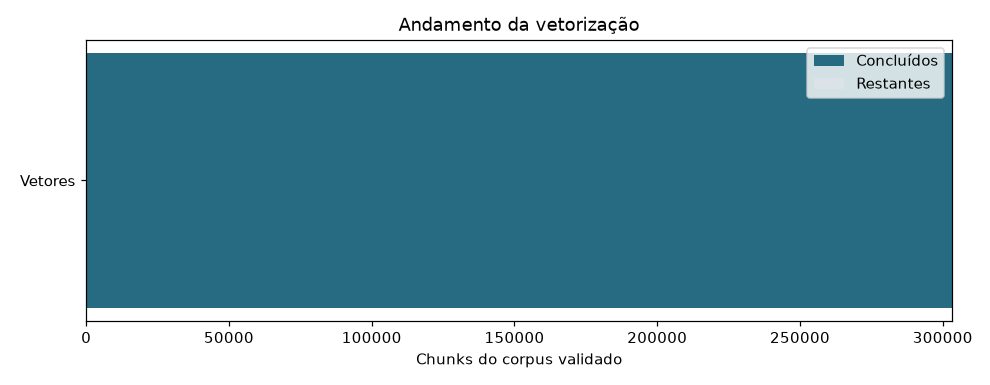

In [7]:
painel.plots(ROOT)

## 8. Diagnóstico, limites e próxima integração

A existência de um vetor não demonstra correção jurídica. Os textos continuam sendo a derivada protegida do notebook 03; o mascaramento de CPF não equivale a anonimização integral. A etapa seguinte, após a coleção estar validada, será avaliar a recuperação e integrar legislação e jurisprudência no mesmo RAG, mantendo fontes identificadas e seus próprios métodos de chunking.

In [8]:
painel.diagnosis(ROOT)

**Diagnóstico:** Embeddings e importação no pgvector concluídos e verificados para esta versão.

**Escopo:** vetores densos BGE-M3, normalizados e vinculados por ID/hash/posição ao texto protegido de cada chunk. Índices aproximados, recuperação conjunta com legislação, RRF, reranker e avaliação de respostas permanecem fora desta etapa.